# Reproducing the experiments

Trustworthy machine learning for employee performance and talent classification (promotion dataset, n = 54,808; IBM HR dataset, n = 1,470).

* `RUN_EXPERIMENTS = False` shows the saved results in `results/` (a few seconds).
* `RUN_EXPERIMENTS = True` re-runs the full pipeline (about 20 minutes on a 16-core CPU).

Data: put `promotion_train.csv` (Kaggle *HR Analytics: Employee Promotion Data*, file `train.csv`) in `data/raw/`; the IBM file is downloaded by `fetch_data.py`.

In [1]:
RUN_EXPERIMENTS = False

In [2]:
import subprocess, sys
steps = ['fetch_data.py', 'ibm_leakage.py', 'run_benchmark.py', 'run_trust.py',
         'run_conformal_repeats.py', 'run_fairness_repeats.py', 'run_talent_box.py',
         'run_box_extras.py', 'make_pipeline_figure.py', 'plot_figures.py', 'plot_talent_box.py',
         'make_graphical_abstract.py']
if RUN_EXPERIMENTS:
    for s in steps:
        print('>>', s)
        subprocess.run([sys.executable, s], check=True)

## 1. Leakage audit of the IBM PerformanceRating task

In [3]:
import pandas as pd
from pathlib import Path
T = Path('..') / 'results' / 'tables'
display(pd.read_csv(T / 'ibm_leakage.csv').round(3))
display(pd.read_csv(T / 'ibm_permutation_test.csv').round(3))

,setting,model,ROC-AUC,PR-AUC,Accuracy@0.5,F1@0.5
0,with PercentSalaryHike,LR,1.000,0.998,0.994,0.980
1,with PercentSalaryHike,RF,1.000,1.000,1.000,1.000
2,with PercentSalaryHike,XGBoost,1.000,1.000,1.000,1.000
3,with PercentSalaryHike,LightGBM,1.000,1.000,1.000,1.000
4,with PercentSalaryHike,CatBoost,1.000,1.000,1.000,1.000
5,without PercentSalaryHike,LR,0.454,0.140,0.846,0.000
6,without PercentSalaryHike,RF,0.516,0.157,0.846,0.000
7,without PercentSalaryHike,XGBoost,0.493,0.157,0.822,0.044
8,without PercentSalaryHike,LightGBM,0.486,0.151,0.832,0.008
9,without PercentSalaryHike,CatBoost,0.496,0.154,0.846,0.000


,model,AUC,perm_mean,perm_sd,p_value,majority_class_accuracy,rule_accuracy
0,LightGBM,0.487,0.5,0.03,0.673,0.846,1.0


## 2. Benchmark (mean over 10 repeated splits)

In [4]:
cols = ['ROC-AUC', 'PR-AUC', 'Accuracy', 'MacroF1', 'Precision', 'Recall', 'MCC', 'Brier', 'ECE', 'latency_ms_per_1k']
for task in ['talent', 'performance', 'potential']:
    s = pd.read_csv(T / f'benchmark_summary_{task}.csv', index_col=0)
    print(task)
    display(s[[c + '_mean' for c in cols]].round(3))

talent


,ROC-AUC_mean,PR-AUC_mean,Accuracy_mean,MacroF1_mean,Precision_mean,Recall_mean,MCC_mean,Brier_mean,ECE_mean,latency_ms_per_1k_mean
model,,,,,,,,,,
CatBoost,0.814,0.553,0.939,0.742,0.798,0.385,0.526,0.051,0.005,1.369
LightGBM,0.816,0.551,0.939,0.741,0.795,0.384,0.525,0.052,0.006,5.567
XGBoost,0.812,0.548,0.939,0.741,0.791,0.382,0.523,0.052,0.007,1.902
LightGBM-CW,0.812,0.540,0.932,0.733,0.677,0.406,0.489,0.143,0.268,4.117
MLP,0.803,0.532,0.935,0.733,0.730,0.385,0.499,0.053,0.010,1.476
RF,0.793,0.524,0.935,0.731,0.756,0.373,0.501,0.054,0.011,10.364
LR,0.785,0.517,0.934,0.731,0.714,0.386,0.493,0.055,0.017,1.089


performance


,ROC-AUC_mean,PR-AUC_mean,Accuracy_mean,MacroF1_mean,Precision_mean,Recall_mean,MCC_mean,Brier_mean,ECE_mean,latency_ms_per_1k_mean
model,,,,,,,,,,
CatBoost,0.617,0.524,0.482,0.420,0.450,0.949,0.140,0.234,0.011,1.315
XGBoost,0.617,0.523,0.486,0.428,0.451,0.940,0.141,0.234,0.011,1.525
RF,0.615,0.521,0.487,0.429,0.451,0.941,0.142,0.236,0.028,8.510
LightGBM-CW,0.613,0.520,0.483,0.421,0.449,0.946,0.138,0.240,0.069,3.057
LightGBM,0.613,0.519,0.483,0.421,0.450,0.944,0.137,0.235,0.009,3.099
LR,0.608,0.517,0.475,0.409,0.446,0.945,0.120,0.236,0.013,0.922
MLP,0.610,0.517,0.481,0.418,0.449,0.945,0.134,0.236,0.018,1.381


potential


,ROC-AUC_mean,PR-AUC_mean,Accuracy_mean,MacroF1_mean,Precision_mean,Recall_mean,MCC_mean,Brier_mean,ECE_mean,latency_ms_per_1k_mean
model,,,,,,,,,,
CatBoost,0.779,0.524,0.939,0.741,0.824,0.377,0.531,0.052,0.005,1.651
LightGBM,0.781,0.523,0.938,0.740,0.787,0.382,0.521,0.053,0.006,3.819
XGBoost,0.777,0.520,0.938,0.739,0.790,0.380,0.521,0.053,0.007,1.831
LightGBM-CW,0.777,0.516,0.935,0.735,0.734,0.387,0.502,0.144,0.274,3.126
MLP,0.769,0.511,0.938,0.734,0.806,0.368,0.516,0.054,0.011,1.715
RF,0.767,0.508,0.938,0.735,0.809,0.369,0.519,0.054,0.010,10.934
LR,0.745,0.501,0.938,0.736,0.781,0.375,0.514,0.056,0.019,1.267


In [5]:
st = pd.read_csv(T / 'stats_tests_talent.csv')
st[st.metric == 'PR-AUC'][['best', 'vs', 'mean_diff', 'p_holm', 'friedman_chi2', 'friedman_p']].round(4)

,best,vs,mean_diff,p_holm,friedman_chi2,friedman_p
0,CatBoost,LR,0.0360,0.0117,58.2857,0.0
1,CatBoost,LightGBM,0.0020,0.0371,58.2857,0.0
2,CatBoost,LightGBM-CW,0.0132,0.0117,58.2857,0.0
3,CatBoost,MLP,0.0212,0.0117,58.2857,0.0
4,CatBoost,RF,0.0292,0.0117,58.2857,0.0
5,CatBoost,XGBoost,0.0052,0.0117,58.2857,0.0


## 3. Nine-box talent placement (boxes 8-9) and prioritisation

In [6]:
p = pd.read_csv(T / 'box_placement_summary.csv')
display(p.round(3))
t = pd.read_csv(T / 'box_tests.csv')
display(t[['comparison', 'set', 'metric', 'mean_ml', 'mean_other', 'rel_gain_%', 'p_holm']].round(4))

,set,method,share_mean,share_std,precision_mean,precision_std,recall_mean,recall_std,lift_mean,lift_std
0,Box 9,Conventional,0.077,0.002,0.274,0.011,0.246,0.011,3.206,0.124
1,Box 9,Dept-normalised,0.083,0.002,0.258,0.013,0.252,0.013,3.017,0.138
2,Box 9,ML-assisted,0.085,0.003,0.295,0.016,0.293,0.013,3.458,0.169
3,Box 9,ML-assisted (age-blind),0.083,0.003,0.297,0.011,0.289,0.015,3.473,0.117
4,Boxes 8-9,Conventional,0.165,0.001,0.191,0.005,0.370,0.008,2.237,0.048
5,Boxes 8-9,Dept-normalised,0.160,0.005,0.177,0.010,0.332,0.017,2.076,0.110
6,Boxes 8-9,ML-assisted,0.167,0.002,0.195,0.005,0.382,0.013,2.282,0.057
7,Boxes 8-9,ML-assisted (age-blind),0.167,0.003,0.193,0.007,0.377,0.011,2.255,0.073


,comparison,set,metric,mean_ml,mean_other,rel_gain_%,p_holm
0,ML-assisted vs Dept-normalised,Box 9,precision,0.2954,0.2577,14.6112,0.0039
1,ML-assisted vs Conventional,Box 9,precision,0.2954,0.2738,7.8882,0.0039
2,ML-assisted (age-blind) vs Dept-normalised,Box 9,precision,0.2967,0.2577,15.1091,0.0039
3,ML-assisted (age-blind) vs Conventional,Box 9,precision,0.2967,0.2738,8.3570,0.0039
4,ML-assisted vs Conventional,Box 9,recall,0.2927,0.2457,19.0941,0.0039
5,ML-assisted vs Dept-normalised,Box 9,recall,0.2927,0.2519,16.1865,0.0039
6,ML-assisted (age-blind) vs Conventional,Box 9,recall,0.2891,0.2457,17.6352,0.0039
7,ML-assisted (age-blind) vs Dept-normalised,Box 9,recall,0.2891,0.2519,14.7633,0.0039
8,ML-assisted vs Dept-normalised,Boxes 8-9,precision,0.1949,0.1773,9.9331,0.0039
9,ML-assisted vs Conventional,Boxes 8-9,precision,0.1949,0.1911,2.0178,0.0059


In [7]:
q = pd.read_csv(T / 'box_prioritisation_summary.csv')
q[q.top_frac.isin([0.1, 0.25, 0.5])][['top_frac', 'ranker', 'precision_mean', 'precision_std', 'female_share_mean']].round(3)

,top_frac,ranker,precision_mean,precision_std,female_share_mean
6,0.10,CatBoost (ML),0.839,0.031,0.329
7,0.10,CatBoost (age-blind),0.847,0.025,0.324
8,0.10,Dept-normalised score,0.821,0.028,0.308
9,0.10,Logistic regression,0.839,0.034,0.335
10,0.10,Random,0.191,0.031,0.340
11,0.10,Training score,0.435,0.027,0.175
18,0.25,CatBoost (ML),0.462,0.024,0.337
19,0.25,CatBoost (age-blind),0.461,0.021,0.340
20,0.25,Dept-normalised score,0.411,0.026,0.302
21,0.25,Logistic regression,0.437,0.023,0.320


In [8]:
display(pd.read_csv(T / 'box_fairness_summary.csv').round(3))
pd.read_csv(T / 'box_deferral_ageblind_runs.csv').groupby('alpha').mean(numeric_only=True).round(3)

,set,method,attribute,selection_rate_diff_mean,selection_rate_diff_std,tpr_diff_mean,tpr_diff_std
0,Box 9,Conventional,age_group,0.022,0.005,0.058,0.034
1,Box 9,Conventional,gender,0.010,0.006,0.024,0.016
2,Box 9,Dept-normalised,age_group,0.009,0.005,0.040,0.028
3,Box 9,Dept-normalised,gender,0.006,0.005,0.028,0.023
4,Box 9,ML-assisted,age_group,0.043,0.008,0.076,0.033
5,Box 9,ML-assisted,gender,0.013,0.006,0.039,0.020
6,Box 9,ML-assisted (age-blind),age_group,0.018,0.008,0.055,0.024
7,Box 9,ML-assisted (age-blind),gender,0.011,0.005,0.038,0.021
8,Boxes 8-9,Conventional,age_group,0.021,0.005,0.045,0.026
9,Boxes 8-9,Conventional,gender,0.028,0.008,0.039,0.021


,repeat,pool,share_ready,share_deferred,share_not_ready,promo_rate_ready,promo_rate_deferred,promo_rate_pool,promoted_missed,deferred_female,deferred_male
alpha,,,,,,,,,,,
0.1,4.5,1354.2,0.586,0.414,0.000,0.272,0.080,0.193,0.0,0.416,0.413
0.2,4.5,1354.2,0.919,0.080,0.001,0.203,0.076,0.193,0.0,0.078,0.082


## 4. Fairness and conformal prediction (talent model)

In [9]:
f = pd.read_csv(T / 'fairness_repeats_summary.csv')
f[['task', 'attribute', 'method', 'F1_mean', 'MCC_mean', 'DPD_mean', 'DPD_std', 'EOD_mean', 'EOD_std']].round(3)

,task,attribute,method,F1_mean,MCC_mean,DPD_mean,DPD_std,EOD_mean,EOD_std
0,performance,age_group,ThresholdOptimizer (equalized odds),0.523,0.148,0.025,0.008,0.044,0.014
1,performance,age_group,Unmitigated,0.554,0.158,0.104,0.059,0.112,0.063
2,performance,gender,ThresholdOptimizer (equalized odds),0.548,0.155,0.014,0.015,0.029,0.014
3,performance,gender,Unmitigated,0.554,0.158,0.042,0.021,0.053,0.026
4,talent,age_group,ThresholdOptimizer (equalized odds),0.371,0.318,0.019,0.010,0.083,0.047
5,talent,age_group,Unmitigated,0.516,0.526,0.011,0.005,0.057,0.038
6,talent,gender,ThresholdOptimizer (equalized odds),0.373,0.323,0.011,0.015,0.037,0.028
7,talent,gender,Unmitigated,0.516,0.526,0.003,0.003,0.034,0.020


In [10]:
c = pd.read_csv(T / 'conformal_repeats_summary.csv')
c[['task', 'method', 'alpha', 'coverage_mean', 'coverage_class1_mean', 'coverage_class1_std', 'ambiguous_mean']].round(3)

,task,method,alpha,coverage_mean,coverage_class1_mean,coverage_class1_std,ambiguous_mean
0,performance,Marginal,0.05,0.949,0.890,0.007,0.810
1,performance,Marginal,0.10,0.899,0.780,0.009,0.673
2,performance,Marginal,0.20,0.801,0.563,0.014,0.436
3,performance,Mondrian,0.05,0.951,0.948,0.006,0.832
4,performance,Mondrian,0.10,0.901,0.897,0.010,0.704
5,performance,Mondrian,0.20,0.801,0.798,0.011,0.463
6,talent,Marginal,0.05,0.951,0.428,0.030,0.032
7,talent,Marginal,0.10,0.901,0.280,0.018,0.000
8,talent,Marginal,0.20,0.802,0.229,0.016,0.000
9,talent,Mondrian,0.05,0.952,0.956,0.008,0.669


## 5. Figures

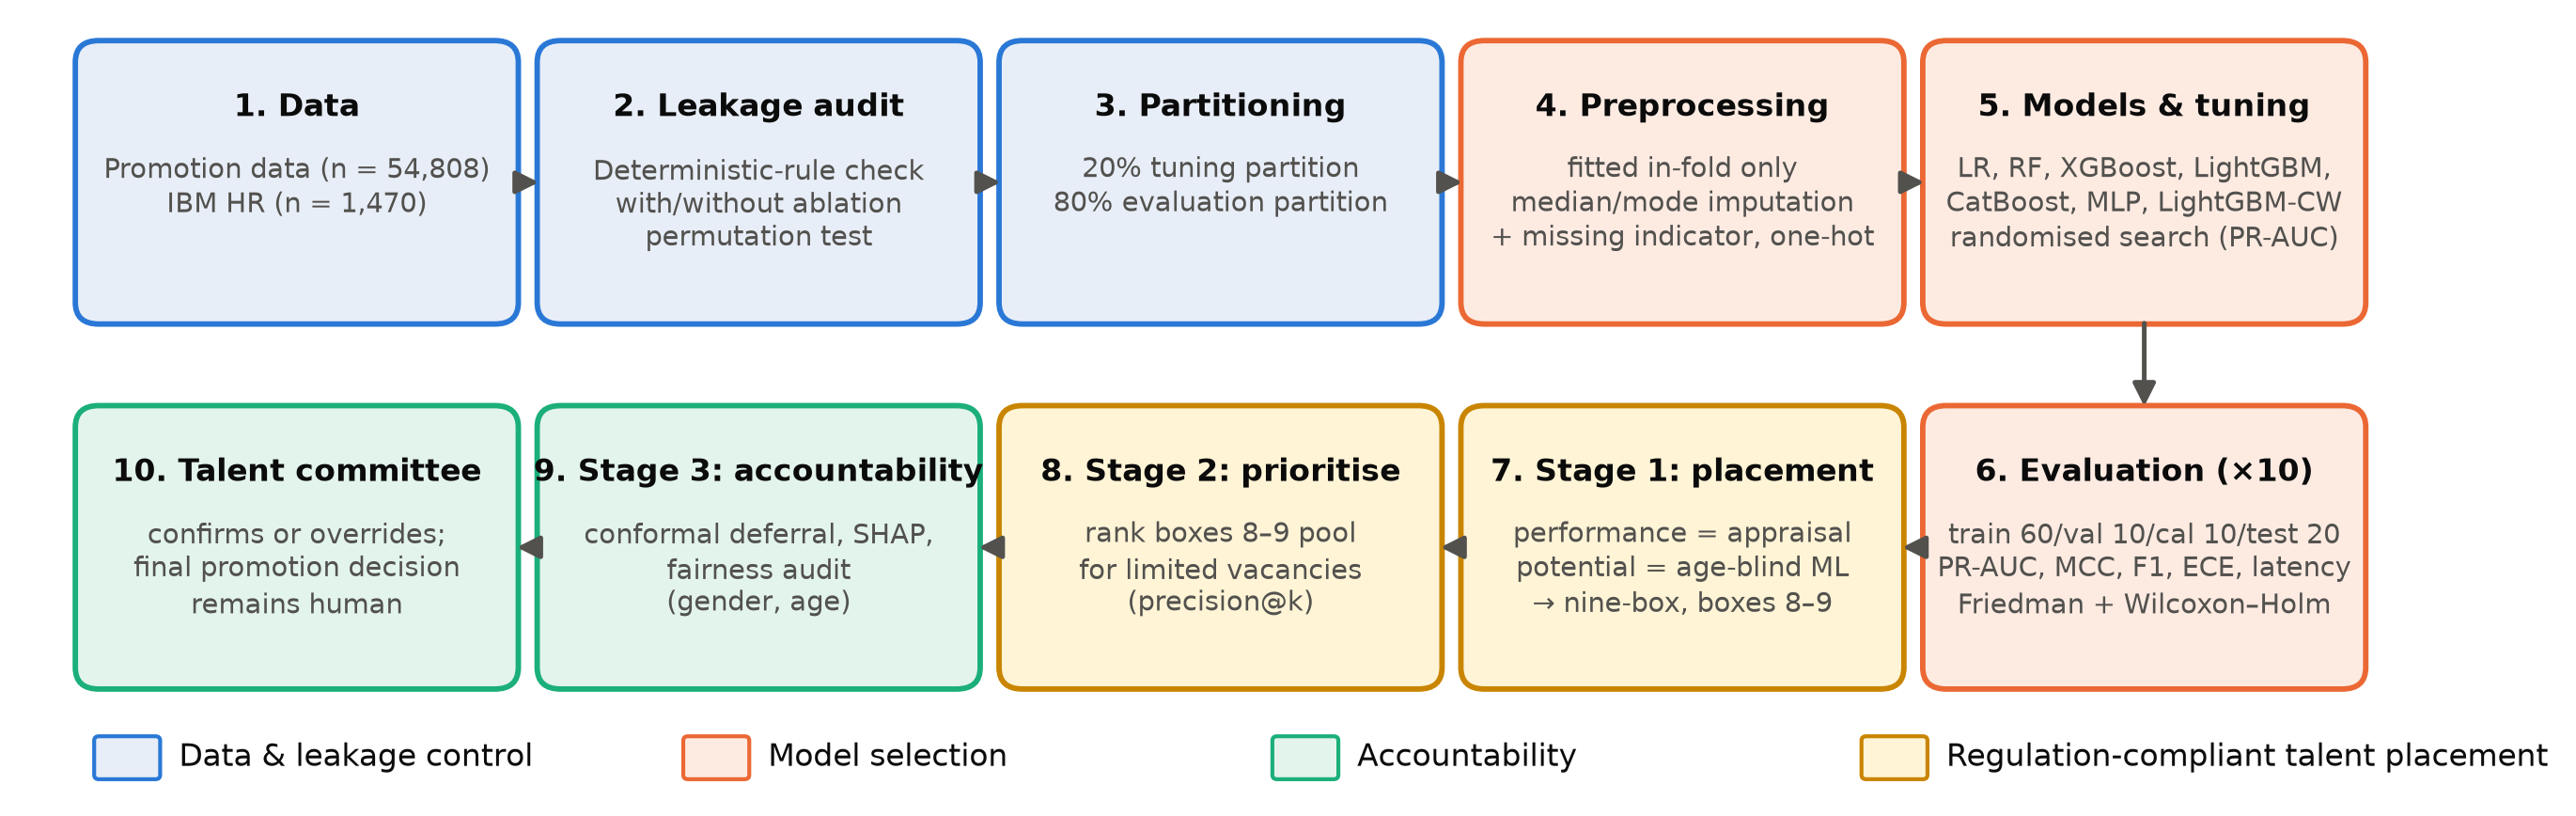

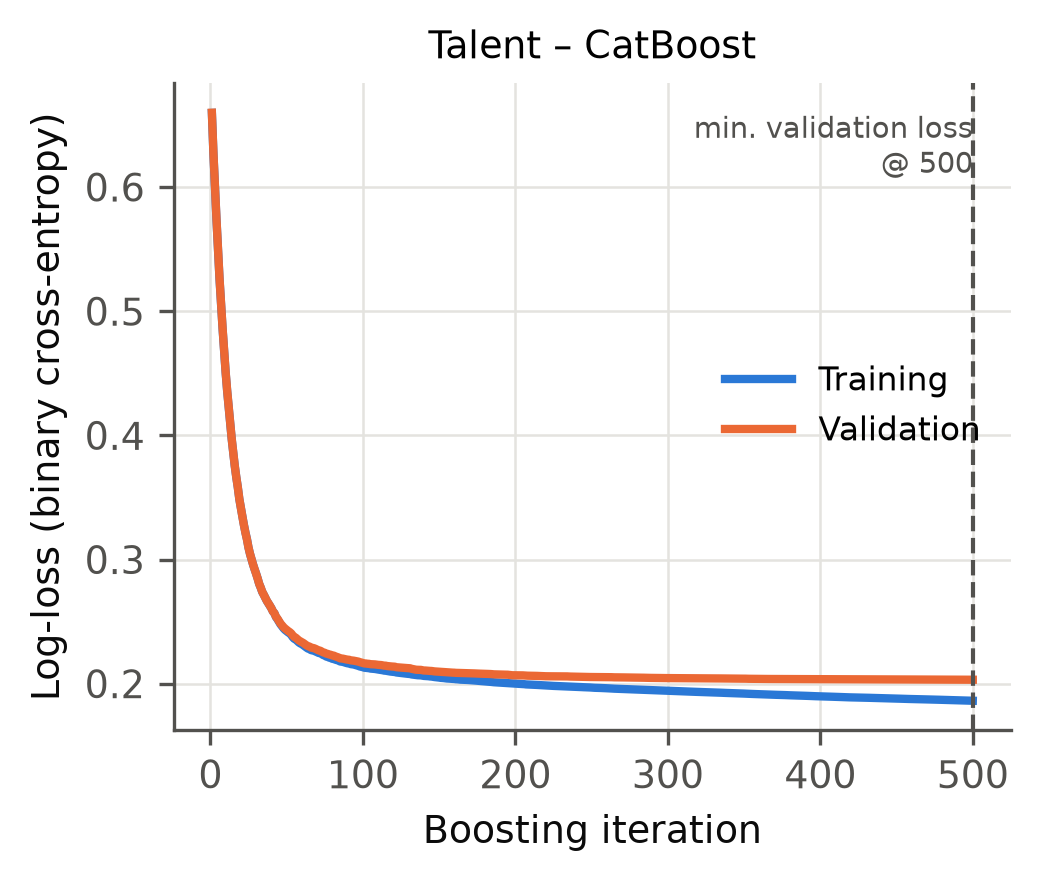

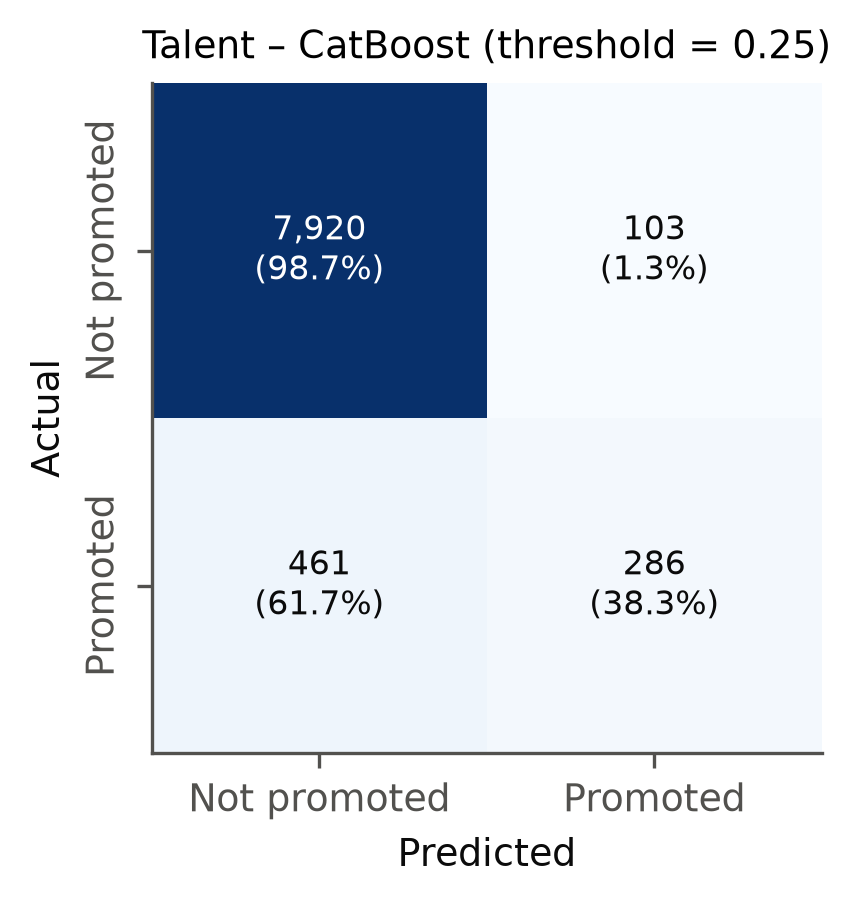

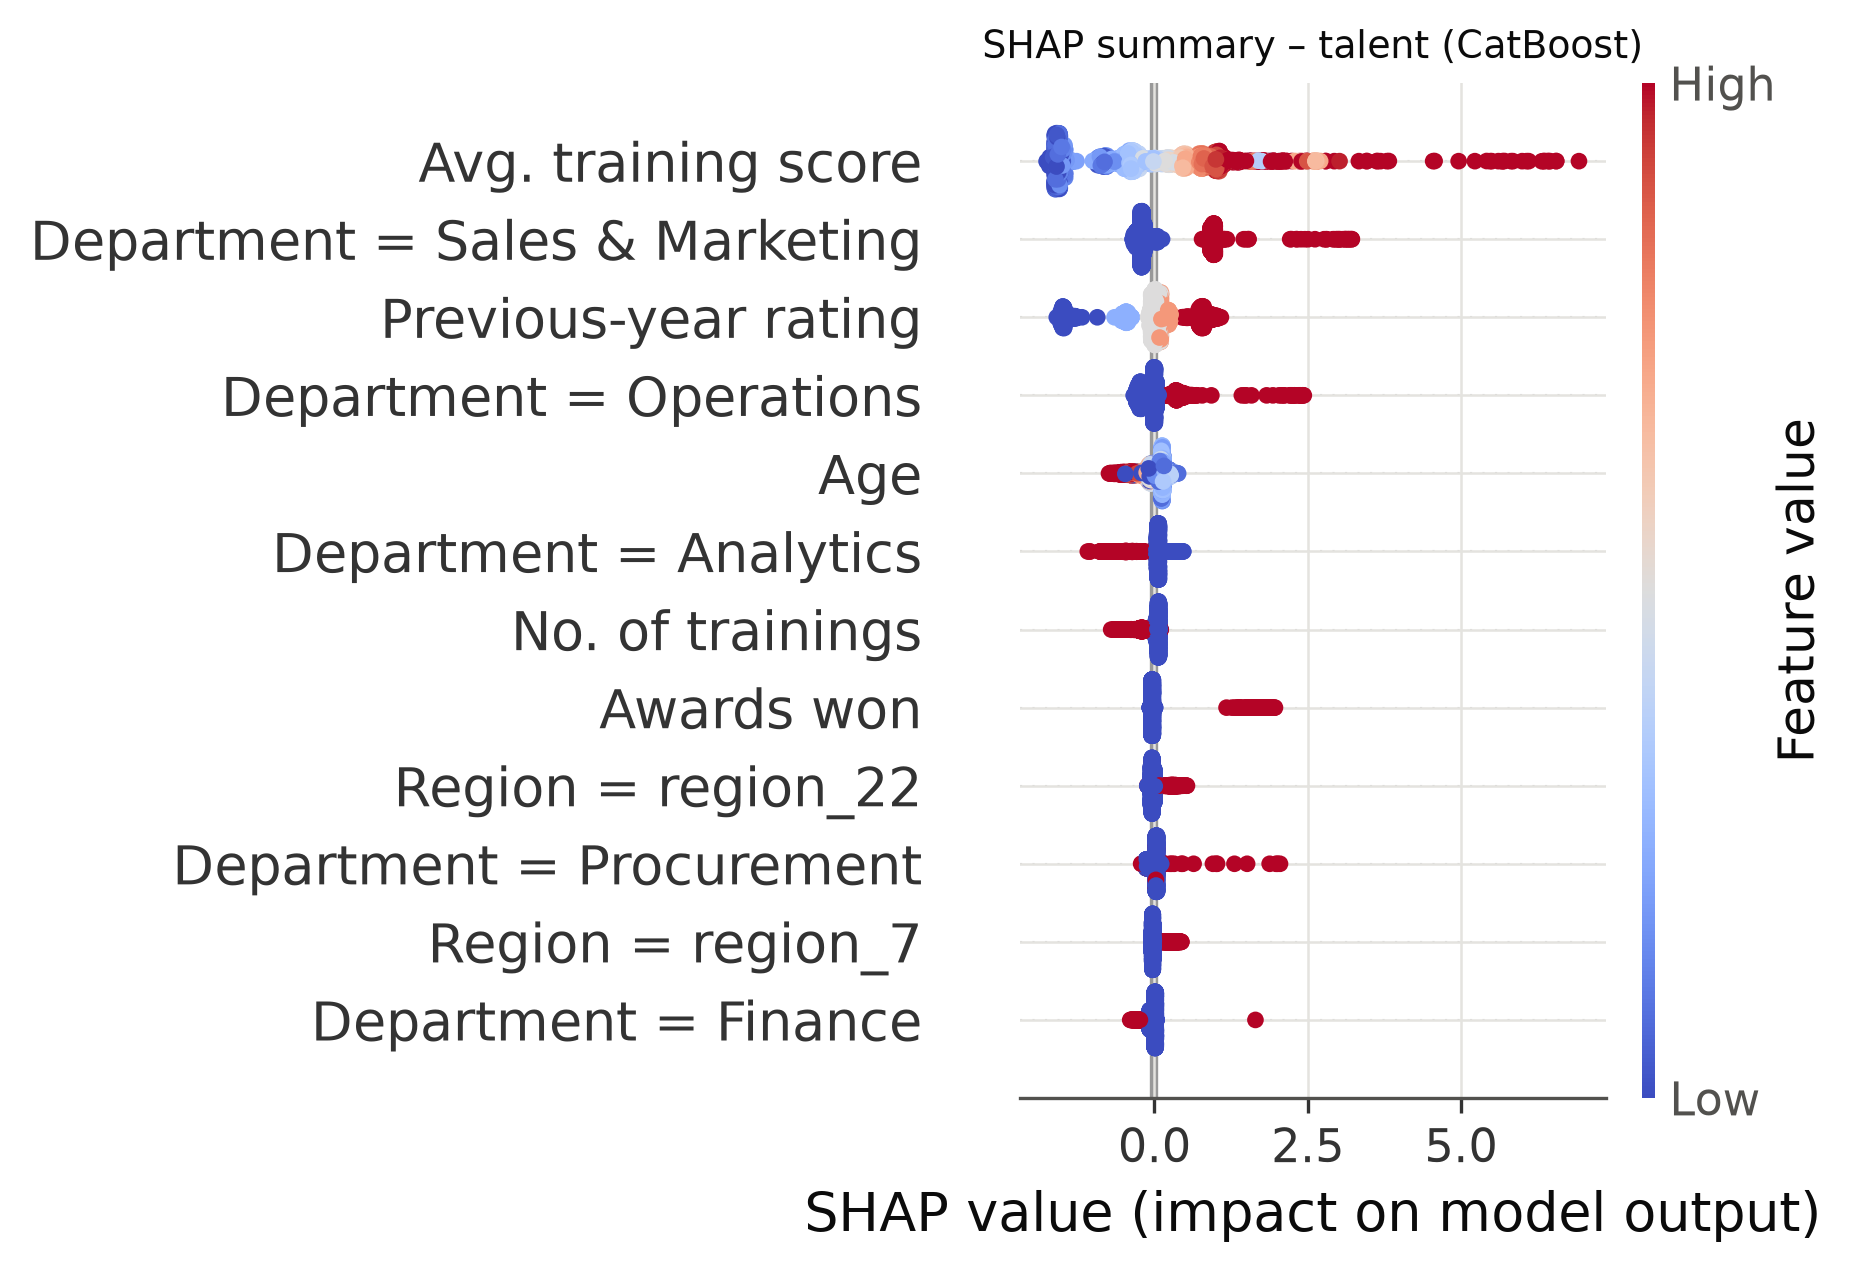

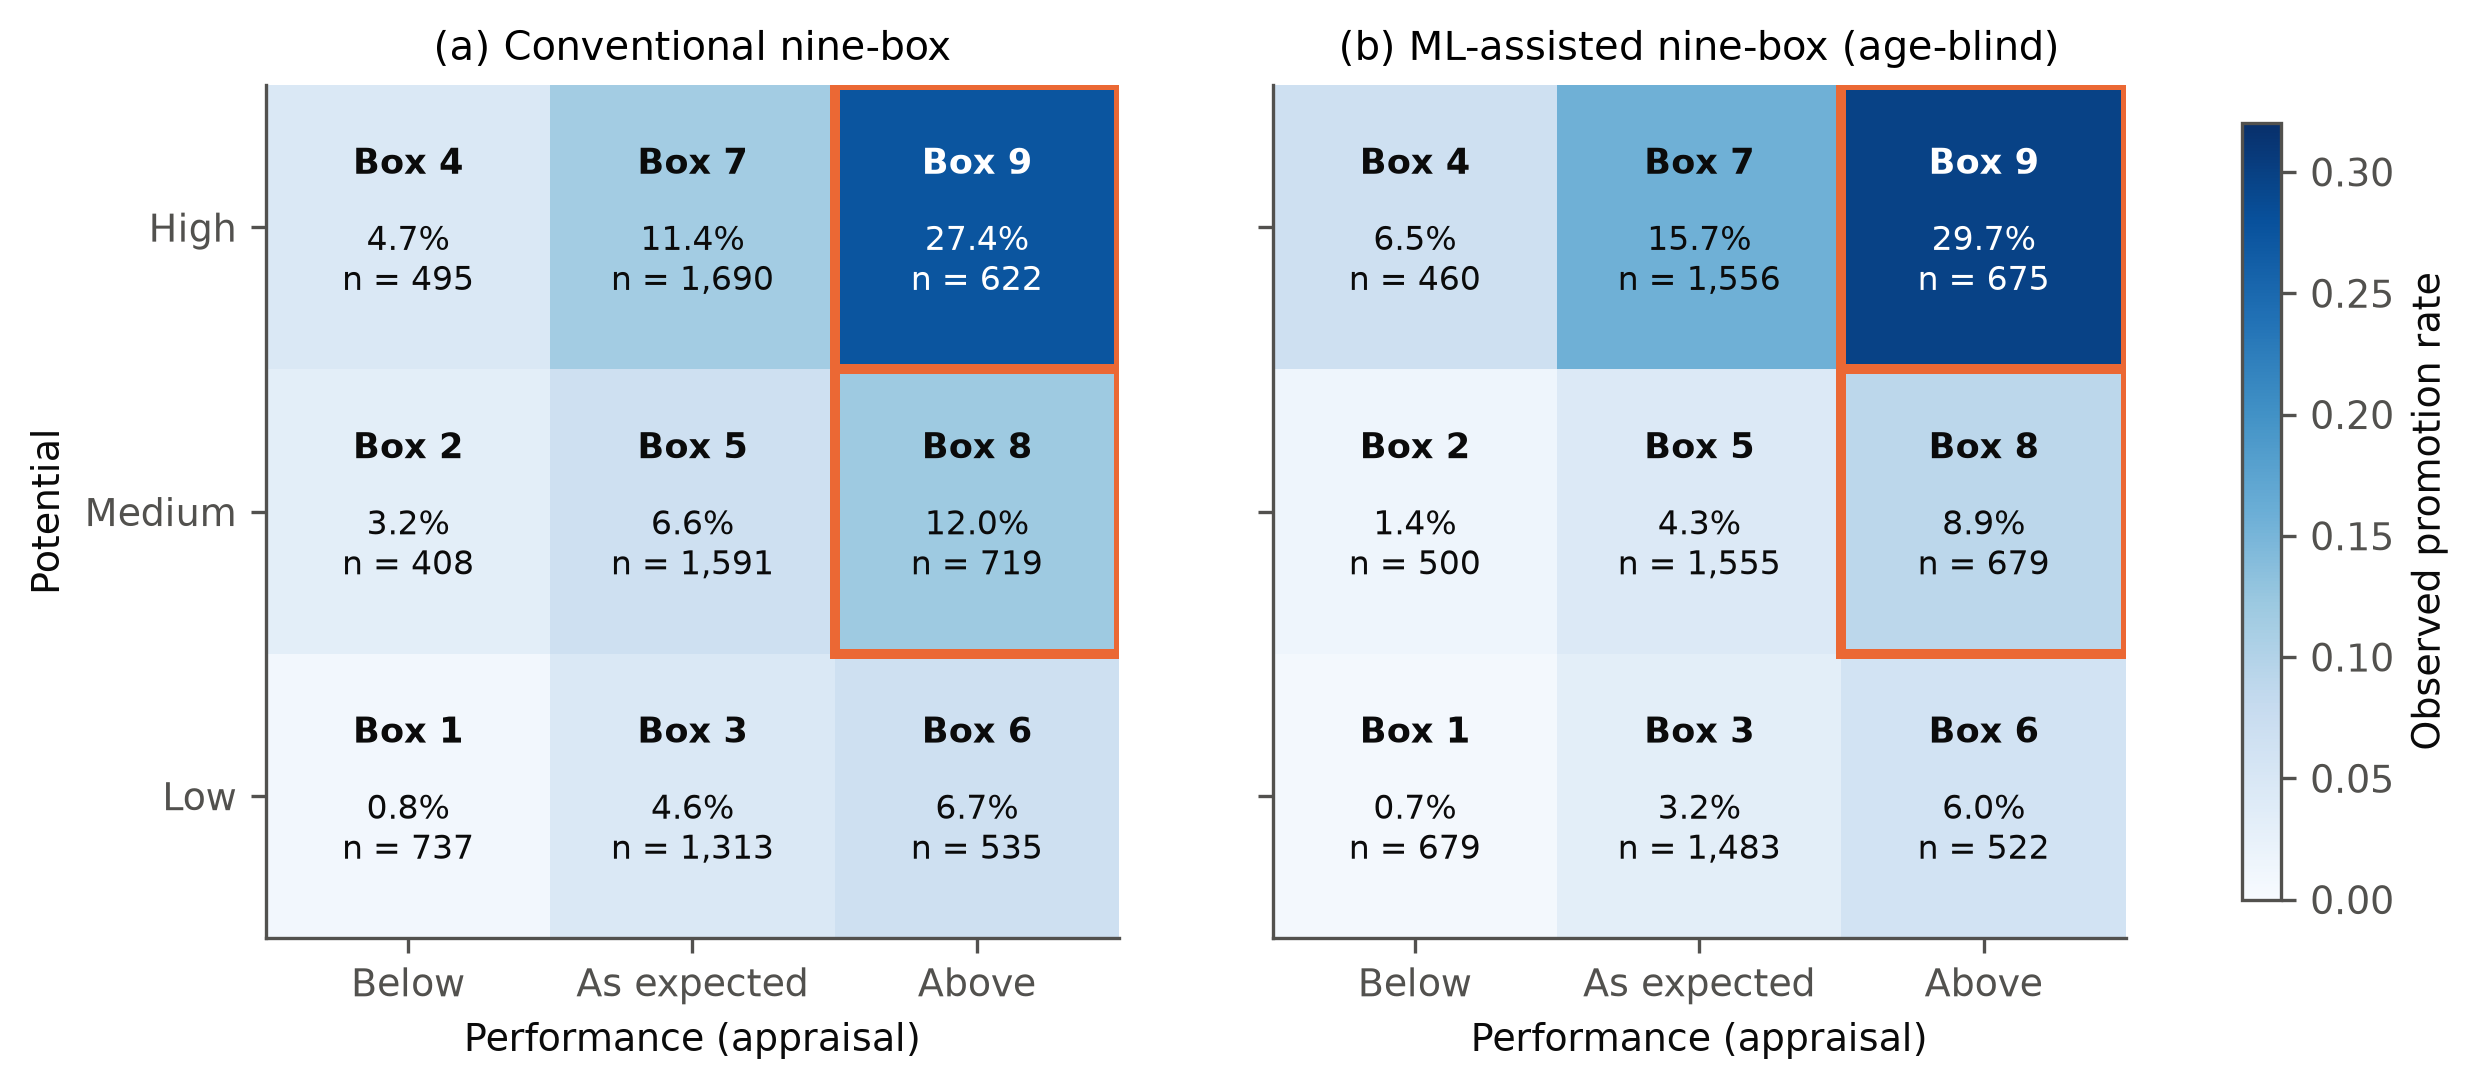

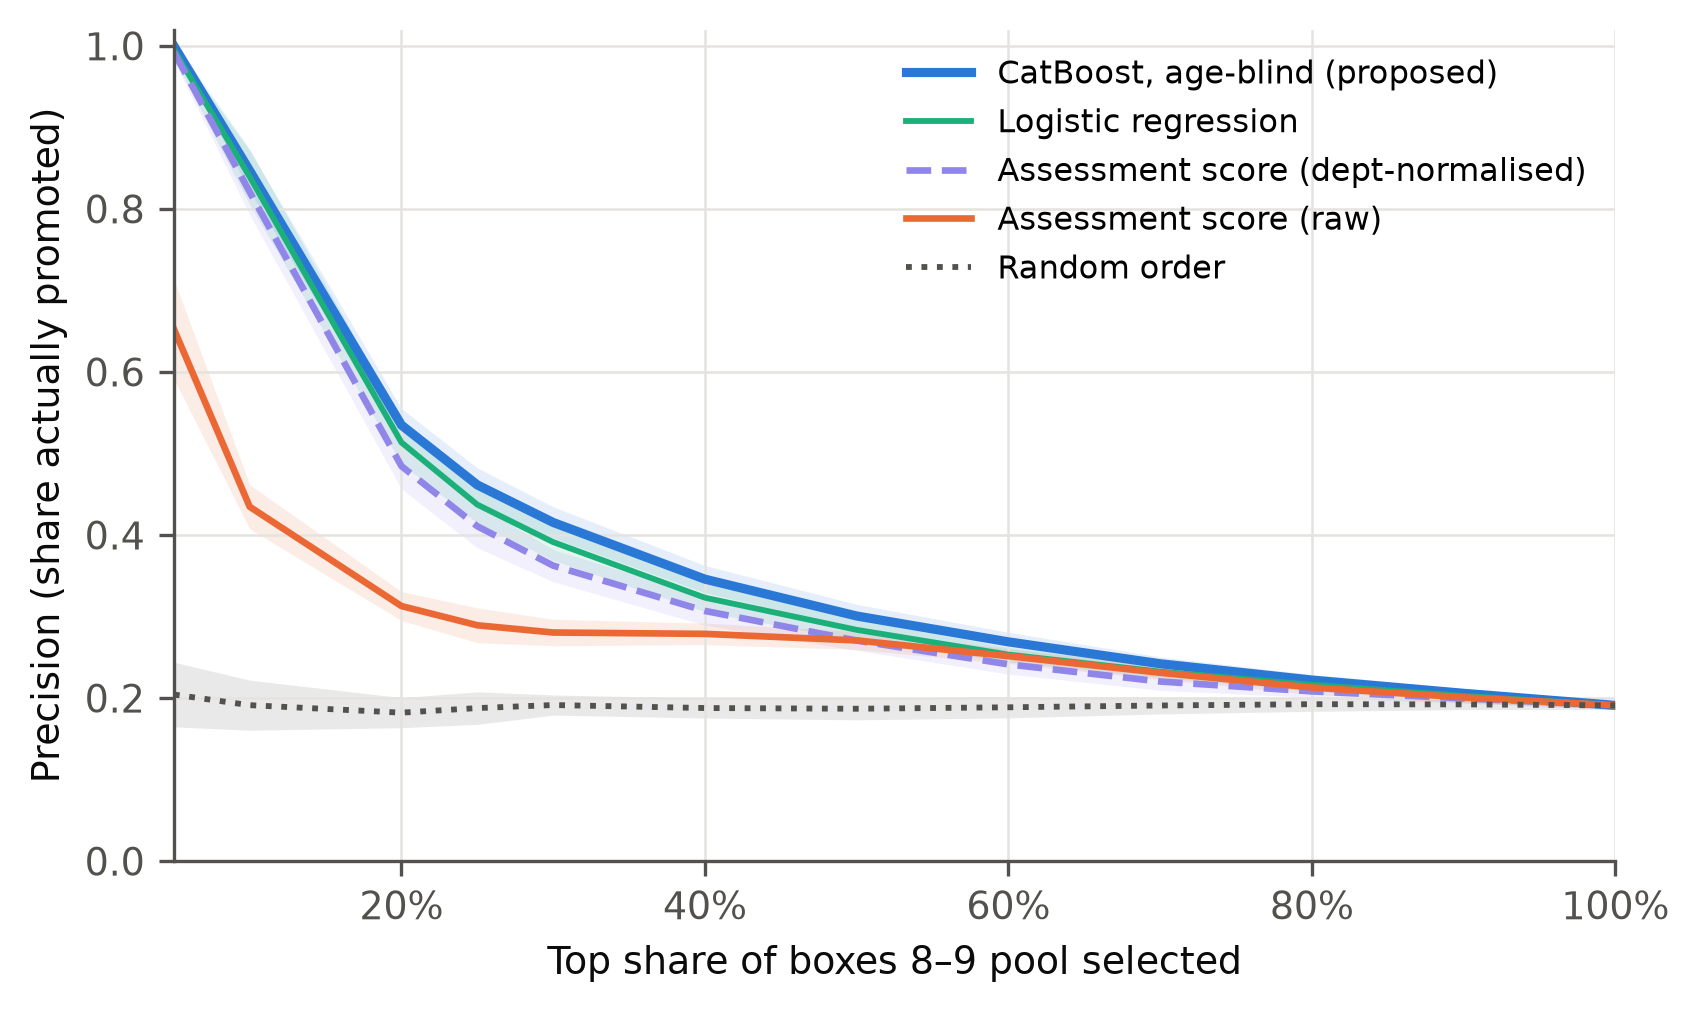

In [11]:
from IPython.display import Image, display
F = Path('..') / 'results' / 'figures'
for f in ['fig_pipeline_en.png', 'conv_tale_en.png', 'cm_tale_en.png', 'fig_shap_beeswarm_talent.png',
          'box_en.png', 'prio_en.png']:
    display(Image(filename=str(F / f), width=600))